Develop and validate k-nearest neighbors (KNN) models, carefully selecting optimal k-values using grid search and cross-validation, and visualizing decision boundaries to evaluate model behavior.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 300

In [4]:
dosage = np.random.uniform(10, 100, n_samples)
biomarker = np.random.uniform(5, 50, n_samples)

In [5]:
radius_squared = (dosage - 55)**2 + (biomarker - 25)**2
target = ((radius_squared < 600) & (dosage > 30)).astype(int)

In [6]:
df_knn = pd.DataFrame({
    'dosage_mg': dosage.round(2),
    'biomarker_ngml': biomarker.round(2),
    'response': target
})

In [7]:
print("Class Distribution:")
print(df_knn['response'].value_counts())

Class Distribution:
response
0    176
1    124
Name: count, dtype: int64


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [24]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

In [25]:
param_grid = {
    'knn__n_neighbors': list(range(1, 31, 2)),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

In [26]:
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'knn__metric': ['euclidean', 'manhattan'],
                         'knn__n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19,
                                              21, 23, 25, 27, 29],
                         'knn__weights': ['uniform', 'distance']},
             scoring='f1')

In [27]:
cv_results = pd.DataFrame(grid_search.cv_results_)

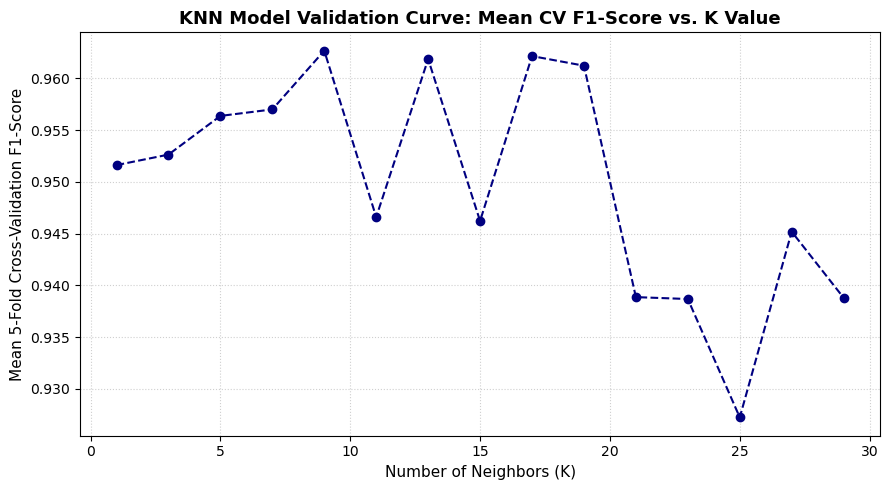

In [28]:
mask = (cv_results['param_knn__weights'] == 'uniform') & (cv_results['param_knn__metric'] == 'euclidean')
filtered_results = cv_results[mask]

plt.figure(figsize=(9, 5))
plt.plot(
    filtered_results['param_knn__n_neighbors'], 
    filtered_results['mean_test_score'], 
    marker='o', 
    color='navy', 
    linestyle='--'
)

plt.title("KNN Model Validation Curve: Mean CV F1-Score vs. K Value", fontsize=13, fontweight='bold')
plt.xlabel("Number of Neighbors (K)", fontsize=11)
plt.ylabel("Mean 5-Fold Cross-Validation F1-Score", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [29]:
x_min, x_max = X['dosage_mg'].min() - 5, X['dosage_mg'].max() + 5
y_min, y_max = X['biomarker_ngml'].min() - 5, X['biomarker_ngml'].max() + 5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

In [30]:
mesh_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
Z = best_model.predict(mesh_points).reshape(xx.shape)

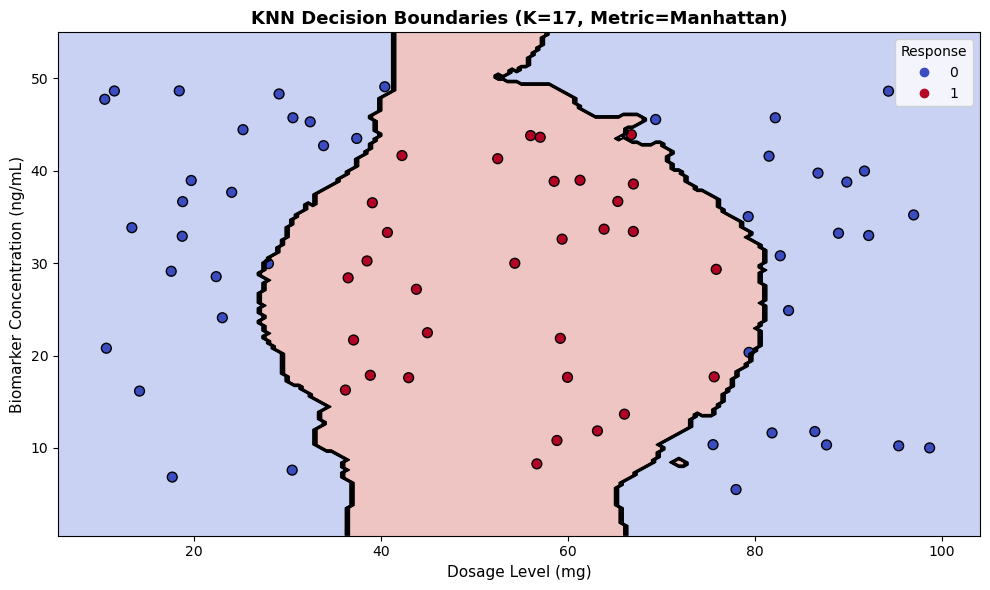

In [33]:
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.contour(xx, yy, Z, colors='black', linewidths=1.0)

scatter = plt.scatter(
    X_test['dosage_mg'], 
    X_test['biomarker_ngml'], 
    c=y_test, 
    cmap='coolwarm', 
    edgecolors='k', 
    s=50
)

best_k = grid_search.best_params_['knn__n_neighbors']
best_metric = grid_search.best_params_['knn__metric'].capitalize()

plt.title(
    f"KNN Decision Boundaries (K={best_k}, Metric={best_metric})", 
    fontsize=13, 
    fontweight='bold'
)
plt.xlabel("Dosage Level (mg)", fontsize=11)
plt.ylabel("Biomarker Concentration (ng/mL)", fontsize=11)
plt.legend(*scatter.legend_elements(), title="Response", loc="upper right")
plt.tight_layout()
plt.show()